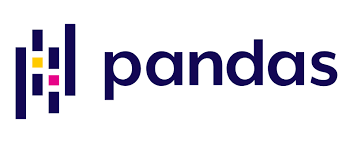

In [2]:
pip list 


Package                 Version
----------------------- -----------
asttokens               3.0.2
colorama                0.4.6
comm                    0.2.3
contourpy               1.4.0
cycler                  0.12.1
debugpy                 1.8.22
executing               2.3.0
fonttools               4.67.0
ipykernel               7.4.0
ipython                 9.17.1
ipython_pygments_lexers 1.1.1
jedi                    0.20.1
jupyter_client          8.10.0
jupyter_core            5.9.1
kiwisolver              1.5.1
matplotlib              3.11.2
matplotlib-inline       0.2.2
nest-asyncio2           1.7.4
numpy                   2.5.4
packaging               26.3
pandas                  3.0.6
parso                   0.8.7
pillow                  13.0.0
pip                     26.2.2
platformdirs            4.13.5
prompt_toolkit          3.0.53
psutil                  7.2.2
pure_eval               0.2.4
Pygments                2.21.0
pyparsing               3.3.3
python-dateutil      

# PANDAS

https://pandas.pydata.org/Pandas_Cheat_Sheet.pdf


1. Creación de DataFrames

Permite definir estructuras de datos bidimensionales con etiquetas en filas y columnas. 
* Por columnas: df = pd.DataFrame({"a":, "b": [7, 8, 9]}, index=[1, 2, 3]) -> Especifica valores columna por columna.
* Por filas: df = pd.DataFrame([[4, 7, 10], [5, 8, 11]], index=[1, 2], columns=['a', 'b', 'c']) -> Especifica valores fila por fila.
* Con MultiIndex (Índices jerárquicos): df = pd.DataFrame(data, index=pd.MultiIndex.from_tuples([('d', 1), ('d', 2)], names=['n', 'v'])). 

2. Remodelación de Datos (Reshaping)

Cambia la disposición, ordenación, índices y nombres de las tablas. 
* pd.melt(df): Reúne columnas y las transforma en filas (unpivot).
* df.pivot(columns='var', values='val'): Expande filas y las transforma en columnas (pivot).
* pd.concat([df1, df2]): Concatena filas de varios DataFrames.
* pd.concat([df1, df2], axis=1): Concatena columnas de varios DataFrames.
* df.sort_values('col'): Ordena las filas por los valores de una columna (menor a mayor). Usa ascending=False para orden inverso.
* df.sort_index(): Ordena el índice del DataFrame.
* df.reset_index(): Restablece el índice a números secuenciales, moviendo el índice anterior a una columna.
* df.rename(columns={'antiguo': 'nuevo'}): Renombra las columnas.
* df.drop(columns=['col1', 'col2']): Elimina las columnas indicadas. 
3. Filtrado y Subconjuntos (Subsets)

Selección de observaciones (filas), variables (columnas) o elementos específicos. 

Filtrado de Filas (Subsets de observaciones)

* df[df.Length > 7]: Extrae filas que cumplen un criterio lógico.
* df.drop_duplicates(): Elimina filas duplicadas.
* df.head(n) / df.tail(n): Selecciona las primeras o últimas n filas.
* df.sample(frac=0.5) / df.sample(n=10): Selecciona una fracción aleatoria o un número fijo n de filas.
* df.nlargest(n, 'col') / df.nsmallest(n, 'col'): Selecciona y ordena las n entradas más grandes o más pequeñas.
* Uso de .query(): Permite expresiones booleanas en cadena de texto, ej: df.query('Length > 7 and Width < 8') o df.query('Name.str.startswith("abc")', engine="python"). 

Filtrado de Columnas (Subsets de variables)

* df[['col1', 'col2']]: Selecciona múltiples columnas por nombre.
* df['col'] o df.col: Selecciona una única columna como Series.
* df.filter(regex='regex'): Selecciona columnas cuyos nombres coinciden con una expresión regular. 

Subconjuntos combinados (Filas y Columnas)

* df.iloc[10:20]: Selecciona las filas de la posición 10 a la 20.
* df.iloc[:, [1, 2, 5]]: Selecciona las columnas en las posiciones numéricas 1, 2 y 5.
* df.loc[:, 'x2':'x4']: Selecciona todas las columnas entre 'x2' y 'x4' inclusive.
* df.loc[df['a'] > 10, ['a', 'c']]: Selecciona las filas que cumplen la condición, y solo las columnas 'a' y 'c'.
* df.at[4, 'A'] / df.iat[1, 2]: Accede de manera rápida a un único valor por etiqueta o por posición de índice, respectivamente. 

4. Lógica y Expresiones Regulares en Python/Pandas

* Operadores lógicos: < (menor), > (mayor), == (igual), != (diferente), <= , >=.
* Funciones lógicas: df.column.isin(valores) (pertenencia a grupo), pd.isnull(obj) (es NaN), pd.notnull(obj) (no es NaN).
* Conectores lógicos: & (and), | (or), ~ (not), ^ (xor), df.any() (alguno), df.all() (todos).
* Ejemplos Regex: '\.' (contiene un punto), 'Length$' (termina en 'Length'), '^Sepal' (empieza por 'Sepal'), '^x[1-5]$' (empieza con 'x' y termina en número del 1 al 5), '^(?!Species$).*' (cualquier cadena excepto 'Species'). 

5. Encadenamiento de Métodos (Method Chaining)

Dado que la mayoría de los métodos de Pandas devuelven un DataFrame, se pueden enlazar operaciones consecutivas entre paréntesis para mejorar la legibilidad del código: 
df = (pd.melt(df)
     .rename(columns={'variable': 'var', 'value': 'val'})
     .query('val >= 200'))

6. Creación de Nuevas Columnas

* df.assign(Area=lambda df: df.Length * df.Height): Calcula e inserta una o más columnas nuevas devolviendo un DataFrame. 
* df['Volume'] = df.Length * df.Height * df.Depth: Añade directamente una nueva columna al DataFrame actual. 
* pd.qcut(df.col, n, labels=False): Divide o agrupa una columna en n cuantiles discretos. 
* Funciones Vectoriales: Operan de manera eficiente en columnas completas o Series:
	* max(axis=1) / min(axis=1): Máximo o mínimo por filas (horizontal).
	* clip(lower=-10, upper=10): Recorta y limita los valores dentro de los umbrales indicados.
	* abs(): Valor absoluto. 

7. Tratamiento de Datos Faltantes (Missing Data)

* df.dropna(): Elimina cualquier fila que contenga algún valor nulo (NA/null).
* df.fillna(value): Reemplaza todos los valores nulos (NA/null) por el valor especificado. 

8. Resumen Estadístico y Exploración (Summarize Data)

* df['w'].value_counts(): Cuenta las frecuencias de cada valor único en una columna.
* len(df): Devuelve el número de filas.
* df.shape: Tupla con el formato (número_de_filas, número_de_columnas).
* df['w'].nunique(): Cuenta la cantidad de valores distintos/únicos en una columna.
* df.describe(): Genera estadísticas descriptivas básicas para cada columna numérica.
* df.info(): Imprime un resumen conciso de la estructura del DataFrame.
* df.memory_usage(): Muestra el uso de memoria de cada columna.
* df.dtypes: Muestra los tipos de datos de cada columna.
* Funciones de agregación comunes: sum(), count() (ignora nulos), median(), quantile([0.25, 0.75]), min(), max(), mean(), var(), std().
* apply(function): Aplica una función personalizada a lo largo del objeto. 

9. Agrupación de Datos (Group Data)

* df.groupby(by="col"): Crea un objeto agrupado por los valores de la columna "col". 
* df.groupby(level="ind"): Agrupa por un nivel específico de un MultiIndex llamado "ind". 
* Funciones para GroupBy:
	* size(): Devuelve el tamaño (conteo) de cada grupo.
	* agg(function): Agrega los grupos aplicando una función específica. 
* Funciones por grupo (mantiene la longitud original del DataFrame):
	* shift(1) / shift(-1): Desplaza o retrasa los valores en una posición.
	* rank(method='dense') / rank(method='min') / rank(method='first') / rank(pct=True): Calcula los rangos de los elementos lidiando de formas distintas con los empates.
	* cumsum() / cummax() / cummin() / cumprod(): Suma, máximo, mínimo o producto acumulado, respectivamente. 

10. Ventanas de Tiempo y Acumulados (Windows)

* df.expanding(): Devuelve un objeto de expansión para aplicar funciones de resumen de manera acumulativa.
* df.rolling(n): Devuelve un objeto de ventana móvil para aplicar funciones de resumen en bloques fijos de tamaño n. 

11. Combinación de Datasets (Joins)

Permite unir dos tablas (adf y bdf) en función de una columna común (on='x1'). 

Joins Estándar

* pd.merge(adf, bdf, how='left', on='x1'): Mantiene todas las filas de adf y une las coincidencias de bdf.
* pd.merge(adf, bdf, how='right', on='x1'): Mantiene todas las filas de bdf y une las coincidencias de adf.
* pd.merge(adf, bdf, how='inner', on='x1'): Retiene únicamente las filas con coincidencias en ambas tablas.
* pd.merge(adf, bdf, how='outer', on='x1'): Retiene absolutamente todos los valores y filas de ambas tablas. 

Joins de Filtrado

* adf[adf.x1.isin(bdf.x1)]: Todas las filas de adf que tienen una coincidencia exacta en bdf.
* adf[~adf.x1.isin(bdf.x1)]: Todas las filas de adf que no tienen coincidencia en bdf. 

Operaciones de Conjunto (Set-like Operations)

* pd.merge(ydf, zdf): Filas compartidas en ambos DataFrames (Intersección).
* pd.merge(ydf, zdf, how='outer'): Filas presentes en cualquiera o en ambos DataFrames (Unión).
* pd.merge(ydf, zdf, how='outer', indicator=True).query('_merge == "left_only"').drop(columns=['_merge']): Filas presentes en ydf pero no en zdf (Diferencia de conjuntos). 

12. Gráficos y Visualización (Plotting)

Pandas se integra nativamente con Matplotlib para dibujar gráficos de tus DataFrames. 
* df.plot(): Gráfico de líneas estándar. 
* df.plot.scatter(x='w', y='h'): Gráfico de dispersión (Scatter plot).
* df.plot.hist(): Histograma de frecuencias. 
* df.plot.pie(): Gráfico de pastel. 
* df.plot.bar(): Gráfico de barras horizontales/verticales. 
* df.plot.boxplot(): Diagrama de caja y bigotes. 
* df.plot.area(): Gráfico de área. 
* df.plot.hexbin(): Gráfico de compartimentos hexagonales. 
* Argumentos combinables de .plot():
	* subplots=True: Genera gráficos separados para cada columna.
	* title="Texto" o title=['col1', 'col2']: Configura el título general o por subgráfico.
	* stacked=True: Apila las barras de las columnas una encima de la otra (para gráficos de barras o áreas).
	* alpha=0.5: Ajusta la transparencia del color al 50%.
	* cumulative=True: Crea un gráfico acumulativo.
	* bins=30: Define la cantidad de intervalos (para histogramas). 

13. Conversión de Tipos de Datos (Changing Type)

* pd.to_numeric(data): Convierte tipos no numéricos a numéricos.
* pd.to_datetime(data): Convierte datos al tipo de fecha datetime.
* pd.to_timedelta(data): Convierte datos al tipo de intervalo timedelta.
* df.astype(type): Fuerza la conversión de los datos a casi cualquier tipo básico o categórico.
* df.infer_objects(): Intenta inferir el tipo de dato idóneo para columnas de tipo objeto.
* df.convert_dtypes(): Convierte las columnas a los mejores tipos posibles soportados de manera inteligente. 

14. Operaciones con Cadenas de Texto Vectorizadas (.str)

Operan eficientemente sobre Series completas de tipo string de manera similar a los métodos nativos de Python: 
* s.str.count(pattern): Cuenta las ocurrencias de un patrón.
* s.str.get(index): Extrae el elemento en el índice indicado.
* s.str.join(sep): Concatena los elementos internos usando un separador.
* s.str.title(): Capitaliza la primera letra de cada palabra.
* s.str.len(): Devuelve la longitud de cada string.
* s.str.cat(): Une todos los elementos de la Serie en un único bloque de texto.
* s.str.partition(sep): Divide el texto basándose en la primera aparición del separador.
* s.str.slice(start, stop, step): Corta/Slices cada elemento de texto.
* s.str.replace(pat, rep): Reemplaza patrones definidos mediante texto o Regex.
* s.str.isalnum(): Comprueba si cada carácter es alfanumérico. 

15. Fechas y Horas (.dt)

Para Series de tipo datetime, el accesor .dt extrae sus componentes individuales: 
* s.dt.year / s.dt.month / s.dt.day: Extrae el año, mes o día como entero.
* s.dt.quarter: Identifica el trimestre del año en el que cae la fecha.
* s.dt.hour / s.dt.minute / s.dt.second: Extrae la hora, minuto o segundo del registro temporal. 

16. Transformación y Mapeado (Mapping)

* s.map(lambda x: 2*x): Aplica una función o diccionario de mapeo a todos los elementos de una Serie individual.
* df.apply(lambda s: s.max() - s.min(), axis=1): Aplica transformaciones avanzadas por columnas o filas (ej. la diferencia entre el máximo y mínimo de cada fila). 

17. Entrada y Salida de Datos (Input/Output)

Formatos legibles por humanos (lectura) y optimizados para rendimiento de escala (escritura): 
* Lectura: pd.read_csv(path), pd.read_html(path), pd.read_excel(path), pd.read_sql(path), pd.read_clipboard() (lee el texto copiado en el portapapeles).
* Escritura: df.to_parquet(path), df.to_feather(path), df.to_hdf(path), df.to_clipboard() (copia la tabla al portapapeles de tu ordenador). 

18. Opciones de Configuración Global de Pandas

Permite controlar el comportamiento y la visualización de la librería a través de la sintaxis pd.options.display.opcion_name = valor. 

Funciones de gestión de opciones

* get_option(option): Recupera el valor actual de una opción.
* set_option(option): Configura una opción.
* reset_option(options): Restablece las opciones a sus configuraciones por defecto.
* describe_option(options): Imprime la descripción detallada de una opción.
* option_context(options): Bloque contextual para ejecutar código con configuraciones temporales que se revierten al salir. 

Opciones más comunes de Visualización (Display options)

* display.max_rows / display.max_columns: Número máximo de filas/columnas a mostrar en la impresión bonita (pretty-print).
* display.expand_frame_repr: Controla si la representación del DataFrame se divide a lo largo de varias páginas.
* display.large_repr: Determina si un DataFrame que excede los límites se trunca o se muestra como un resumen.
* display.precision: Cantidad de decimales de precisión en las salidas.
* display.max_colwidth: Ancho máximo de las columnas; los textos más largos se truncarán.
* display.max_info_columns: Número máximo de columnas mostradas al llamar a df.info().
* display.chop_threshold: Umbral de redondeo a cero para valores numéricos extremadamente pequeños.
* display.colheader_justify: Controla la justificación del texto en las cabeceras de columna. 


# Intro Pandas

En un nivel muy básico, los objetos Pandas pueden ser considerados como **versiones mejoradas de los arrays estructurados de NumPy en los que las filas y columnas se identifican con etiquetas en lugar de simples índices enteros.**
Como veremos en el transcurso de este capítulo, Pandas proporciona una gran cantidad de herramientas útiles, métodos y funcionalidad sobre las estructuras de datos básicas, pero **casi todo lo que sigue requerirá una comprensión de lo que son estas estructuras**.
Por lo tanto, antes de seguir adelante, vamos a introducir estas tres estructuras de datos fundamentales de Pandas: la ``Serie``, ``DataFrame``, y ``Index``.

Comenzaremos nuestras sesiones de código con las importaciones estándar de NumPy y Pandas:

In [1]:
import numpy as np
import pandas as pd

## El objeto Serie de Pandas

Una ``Serie`` de Pandas es un array unidimensional de datos indexados.
Se puede crear a partir de una lista o un array de la siguiente manera:

In [4]:
data_numpy = np.array([1.5, 1.6, 1.75, 1.80])
data_numpy

array([1.5 , 1.6 , 1.75, 1.8 ])

In [5]:
print(type(data_numpy))

<class 'numpy.ndarray'>


In [6]:
# Heights of class
data = pd.Series([1.5, 1.6, 1.75, 1.80])
data

0    1.50
1    1.60
2    1.75
3    1.80
dtype: float64

In [7]:
print(type(data))

<class 'pandas.Series'>


In [9]:
print(data)

0    1.50
1    1.60
2    1.75
3    1.80
dtype: float64


In [11]:
data2 = pd.Series([1.5, 1.6, 1.75, 1.80, " "]) # object es string
data2

0     1.5
1     1.6
2    1.75
3     1.8
4        
dtype: object

Como vemos en la salida, la ``Serie`` envuelve tanto una secuencia de valores como una secuencia de índices, a los que podemos acceder con los atributos ``values`` e ``index``.
Los ``valores`` son simplemente un array de NumPy:

In [12]:
data.values

array([1.5 , 1.6 , 1.75, 1.8 ])

El ``índice`` es un objeto tipo array del tipo ``pd.Index``, del que hablaremos con más detalle.

In [13]:
data.index

RangeIndex(start=0, stop=4, step=1)

Al igual que con un array de NumPy, se puede acceder a los datos por el índice asociado mediante la conocida notación de corchetes de Python:

In [14]:
data

0    1.50
1    1.60
2    1.75
3    1.80
dtype: float64

In [15]:
data[1]

np.float64(1.6)

In [20]:
otra_serie = data[1:]
print(otra_serie) #se lleva el índice de "data", y "otra serie" comienza con el índice 1

print(data)

1    1.60
2    1.75
3    1.80
dtype: float64
0    1.50
1    1.60
2    1.75
3    1.80
dtype: float64


In [16]:
otra_serie = data[1:4]
print(otra_serie)
print(data)

1    1.60
2    1.75
3    1.80
dtype: float64
0    1.50
1    1.60
2    1.75
3    1.80
dtype: float64


In [17]:
print(type(otra_serie))

<class 'pandas.Series'>


In [18]:
otra_serie[0:2]

1    1.60
2    1.75
dtype: float64

Sin embargo, como veremos, **la ``Serie`` de Pandas es mucho más general y flexible que el array unidimensional de NumPy** que emula.

### ``Series`` como matriz NumPy 

Por lo que hemos visto hasta ahora, puede parecer que el objeto ``Series`` es básicamente intercambiable con un array unidimensional de NumPy.
**La diferencia esencial es la presencia del índice**: mientras que el array de Numpy tiene un índice entero *implícitamente definido* que se utiliza para acceder a los valores, las ``Series`` de Pandas tienen un índice ***explícitamente definido*** asociado a los valores.

Esta definición explícita del índice proporciona al objeto ``Series`` capacidades adicionales. Por ejemplo, el índice no necesita ser un entero, sino que puede consistir en valores de cualquier tipo deseado.
Por ejemplo, **si lo deseamos, podemos utilizar cadenas como índice:**


In [21]:
data = pd.Series([1.5, 1.6, 1.75, 1.80], index=['Jane', 'Joe', 'Susan', 'Mike'])
data

Jane     1.50
Joe      1.60
Susan    1.75
Mike     1.80
dtype: float64

In [22]:
data.values

array([1.5 , 1.6 , 1.75, 1.8 ])

In [23]:
np.array(data.index)

array(['Jane', 'Joe', 'Susan', 'Mike'], dtype=object)

Y el acceso al artículo funciona como se esperaba:

In [32]:
# data[2] #nos devuelve un KeyError; una key válida podría ser un dni, pero mejor un ID numérico

data["Jane"] #este índice podría estar duplicado... no está bien hecho, pero lo permite

np.float64(1.6)

In [33]:
pd.__version__

'3.0.6'

In [34]:
data = pd.Series([1.6, 1.6, 1.6, 1.80], index=['Jane', 'Susan', 'Susan', 'Susan'])
data

Jane     1.6
Susan    1.6
Susan    1.6
Susan    1.8
dtype: float64

In [35]:
data['Susan']

Susan    1.6
Susan    1.6
Susan    1.8
dtype: float64

Incluso podemos utilizar índices no contiguos o no secuenciales:

In [36]:
data = pd.Series([1.5, 1.6, 1.75, 1.80],index = ["PEPE", "JUAN", "LUIS", "DIEGO"])
data

PEPE     1.50
JUAN     1.60
LUIS     1.75
DIEGO    1.80
dtype: float64

In [38]:
data[1:-1] # Slicing por posición con hilos, o por índice

JUAN    1.60
LUIS    1.75
dtype: float64

In [29]:
data[2] # Selección por valor del índice

C:\Users\Diego Nuñez\AppData\Local\Temp\ipykernel_12944\3455470185.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  data[2] # Selección por valor del índice


np.float64(1.75)

### Series como diccionario especializado

De esta manera, puedes pensar en una ``Serie`` de Pandas como una especialización de un diccionario de Python.
Un diccionario es una estructura que asigna claves arbitrarias a un conjunto de valores arbitrarios, y una ``Serie`` es una estructura que asigna claves tipificadas a un conjunto de valores tipificados.
Esta tipificación es importante: al igual que el código compilado de tipo específico detrás de un array de NumPy lo hace más eficiente que una lista de Python para ciertas operaciones, la información de tipo de una ``Serie`` de Pandas la hace mucho más eficiente que los diccionarios de Python para ciertas operaciones.

La analogía entre ``Series`` y diccionario se puede hacer aún más clara construyendo un objeto ``Series`` directamente desde un diccionario de Python:

In [43]:
population_dict = {'California': 38332521,
                   'Texas': 26448193,
                   'New York': 19651127,
                   'Florida': 19552860,
                   'Illinois': 12882135}
print(population_dict, type(population_dict))

population = pd.Series(population_dict)
print(population, type(population))

{'California': 38332521, 'Texas': 26448193, 'New York': 19651127, 'Florida': 19552860, 'Illinois': 12882135} <class 'dict'>
California    38332521
Texas         26448193
New York      19651127
Florida       19552860
Illinois      12882135
dtype: int64 <class 'pandas.Series'>


Por defecto, se creará una ``Serie`` donde el índice se extrae de las claves ordenadas.
A partir de aquí, se puede realizar el típico acceso a los elementos de estilo diccionario:

In [44]:
population_dict['California']

38332521

In [45]:
population['California']

np.int64(38332521)

Sin embargo, a diferencia de un diccionario, ``Series`` también admite operaciones de tipo matriz, como el corte:

In [46]:
population['California':'Florida']

California    38332521
Texas         26448193
New York      19651127
Florida       19552860
dtype: int64

In [48]:
population[0:4]

California    38332521
Texas         26448193
New York      19651127
Florida       19552860
dtype: int64

In [50]:
pd.Series?


Init signature:
pd.Series(
    data=None,
    index=None,
    dtype: 'Dtype | None' = None,
    name=None,
    copy: 'bool | None' = None,
) -> 'None'
Docstring:     
One-dimensional ndarray with axis labels (including time series).

Labels need not be unique but must be a hashable type. The object
supports both integer- and label-based indexing and provides a host of
methods for performing operations involving the index. Statistical
methods from ndarray have been overridden to automatically exclude
missing data (currently represented as NaN).

Operations between Series (+, -, /, \*, \*\*) align values based on their
associated index values-- they need not be the same length. The result
index will be the sorted union of the two indexes.

Parameters
----------
data : array-like, Iterable, dict, or scalar value
    Contains data stored in Series. If data is a dict, argument order is
    maintained. Unordered sets are not supported.
index : array-like or Index (1d)
    Values must be hash

In [56]:
pd.Series.__doc__

'\n    One-dimensional ndarray with axis labels (including time series).\n\n    Labels need not be unique but must be a hashable type. The object\n    supports both integer- and label-based indexing and provides a host of\n    methods for performing operations involving the index. Statistical\n    methods from ndarray have been overridden to automatically exclude\n    missing data (currently represented as NaN).\n\n    Operations between Series (+, -, /, \\*, \\*\\*) align values based on their\n    associated index values-- they need not be the same length. The result\n    index will be the sorted union of the two indexes.\n\n    Parameters\n    ----------\n    data : array-like, Iterable, dict, or scalar value\n        Contains data stored in Series. If data is a dict, argument order is\n        maintained. Unordered sets are not supported.\n    index : array-like or Index (1d)\n        Values must be hashable and have the same length as `data`.\n        Non-unique index values are a

### Construyendo objetos Series

Ya hemos visto algunas formas de construir una ``Serie`` de Pandas desde cero; todas ellas son alguna versión de lo siguiente:

```python
pd.Series(data, index=index)
```

donde ``índice`` es un argumento opcional, y ``datos`` puede ser una de muchas entidades.

Por ejemplo, ``data`` puede ser una lista o un array de NumPy, en cuyo caso ``index`` es por defecto una secuencia de enteros:

In [51]:
help (pd.Series)

Help on class Series in module pandas:

class Series(pandas.core.base.IndexOpsMixin, pandas.core.generic.NDFrame)
 |  Series(data=None, index=None, dtype: 'Dtype | None' = None, name=None, copy: 'bool | None' = None) -> 'None'
 |
 |  One-dimensional ndarray with axis labels (including time series).
 |
 |  Labels need not be unique but must be a hashable type. The object
 |  supports both integer- and label-based indexing and provides a host of
 |  methods for performing operations involving the index. Statistical
 |  methods from ndarray have been overridden to automatically exclude
 |  missing data (currently represented as NaN).
 |
 |  Operations between Series (+, -, /, \*, \*\*) align values based on their
 |  associated index values-- they need not be the same length. The result
 |  index will be the sorted union of the two indexes.
 |
 |  Parameters
 |  ----------
 |  data : array-like, Iterable, dict, or scalar value
 |      Contains data stored in Series. If data is a dict, arg

In [53]:
pd.Series([]) #estructura de serie vacía

Series([], dtype: object)

In [49]:
pd.Series([2, 4, 6])

0    2
1    4
2    6
dtype: int64

``data`` puede ser un escalar, que se repite para llenar el índice especificado:

In [38]:
pd.Series(5, index=[100, 200, 300])

100    5
200    5
300    5
dtype: int64

``data`` puede ser un diccionario, en el que ``index`` es por defecto las claves ordenadas del diccionario:

In [ ]:
pd.Series({2:'a', 1:'b', 3:'c'})

2    a
1    b
3    c
dtype: object

En cada caso, el índice puede establecerse explícitamente si se prefiere un resultado diferente:

In [45]:
pd.Series({2:'a', 1:'b', 3:'c'}, index=[3, 2])

3    c
2    a
dtype: object

Observe que, en este caso, la ``Serie`` se rellena sólo con las claves identificadas explícitamente.

<table align="left">
 <tr><td width="80"><img src="./img/ejercicio.png" style="width:auto;height:auto"></td>
     <td style="text-align:left">
         <h3>Ejercicio series ventas</h3>

      
<ol>
    <li>Calcula el total de ventas para todo el año.</li>
    <li>Encuentra el mes con el mayor número de ventas.</li>
    <li>Encuentra el mes con el menor número de ventas.</li>
    <li>Calcula el promedio de ventas mensuales.</li>
    <li>Encuentra los meses en los que las ventas superaron el promedio.</li>
</ol>
         
 </td></tr>
</table>

In [58]:
lista_ventas = [15000, 18000, 22000, 19500, 21000, 23000, 24000, 20000, 18500, 17000, 16000, 17500, 33000]
lista_meses = ["Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio", "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre", "Enero"]
ventas_mensuales = pd.Series(lista_ventas, index=lista_meses)
ventas_mensuales

Enero         15000
Febrero       18000
Marzo         22000
Abril         19500
Mayo          21000
Junio         23000
Julio         24000
Agosto        20000
Septiembre    18500
Octubre       17000
Noviembre     16000
Diciembre     17500
Enero         33000
dtype: int64

In [60]:
#Sumatorios

print(np.sum(ventas_mensuales))
print(ventas_mensuales.sum())

264500
264500


In [62]:
#Valor máximo

print(ventas_mensuales.max())
ventas_mensuales.max()

33000


np.int64(33000)

In [63]:
ventas_mensuales == 33000

Enero         False
Febrero       False
Marzo         False
Abril         False
Mayo          False
Junio         False
Julio         False
Agosto        False
Septiembre    False
Octubre       False
Noviembre     False
Diciembre     False
Enero          True
dtype: bool

In [51]:
ventas_mensuales == ventas_mensuales.max()

Enero         False
Febrero       False
Marzo         False
Abril         False
Mayo          False
Junio         False
Julio         False
Agosto        False
Septiembre    False
Octubre       False
Noviembre     False
Diciembre     False
Enero          True
dtype: bool

In [64]:
ventas_mensuales[ventas_mensuales == ventas_mensuales.max()].values[0] #máscara

np.int64(33000)

In [61]:
print(ventas_mensuales.argmax())
print(ventas_mensuales[ventas_mensuales.argmax()])
print(ventas_mensuales.idxmax())

12
33000
Enero


C:\Users\Diego Nuñez\AppData\Local\Temp\ipykernel_12944\3432149049.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(ventas_mensuales[ventas_mensuales.argmax()])


In [62]:
ventas_mensuales

Enero         15000
Febrero       18000
Marzo         22000
Abril         19500
Mayo          21000
Junio         23000
Julio         24000
Agosto        20000
Septiembre    18500
Octubre       17000
Noviembre     16000
Diciembre     17500
Enero         33000
dtype: int64

In [ ]:
ventas_mensuales.nlargest(1).index[0] #el string mas largo, o el número más alto

'Enero'

In [69]:
print(ventas_mensuales.idxmin()) #valor minimo de índices

Enero


In [123]:
print(ventas_mensuales.mean())

20346.153846153848


In [ ]:
ventas_mensuales[ventas_mensuales > ventas_mensuales.mean()].index #todos los mayores a la media


Index(['Marzo', 'Mayo', 'Junio', 'Julio', 'Enero'], dtype='object')

In [70]:
ventas_mensuales[ventas_mensuales > ventas_mensuales.mean()]

Marzo    22000
Mayo     21000
Junio    23000
Julio    24000
Enero    33000
dtype: int64

## El objeto Pandas DataFrame

La siguiente estructura fundamental en Pandas es el ``DataFrame``.
Al igual que el objeto ``Series`` de la sección anterior, el ``DataFrame`` puede ser **pensado como una generalización de un array de NumPy, o como una especialización de un diccionario de Python.**
Ahora echaremos un vistazo a cada una de estas perspectivas.

### DataFrame como matriz generalizada de NumPy
Si una ``Serie`` es un análogo de un array unidimensional con índices flexibles, un **``DataFrame`` es un análogo de un array bidimensional con índices de fila y nombres de columna flexibles.**
Al igual que se puede pensar en una matriz bidimensional como una secuencia ordenada de columnas unidimensionales alineadas, se puede pensar en un ``DataFrame`` como una secuencia de objetos ``Series`` alineados.
Aquí, por "alineado" queremos decir que **comparten el mismo índice.**

Para demostrarlo, construyamos primero una nueva ``Serie`` que enumere el área de cada uno de los cinco estados discutidos en la sección anterior:

In [71]:
df = pd.DataFrame([1,2,3,4])
df

,0
0,1
1,2
2,3
3,4


In [73]:
df = pd.DataFrame([[1,2,3,4], [5,6,7,8]])
df

,0,1,2,3
0,1,2,3,4
1,5,6,7,8


In [74]:
df = pd.DataFrame([1,2,3,4,5,6,7,8])
df

,0
0,1
1,2
2,3
3,4
4,5
5,6
6,7
7,8


In [75]:
area_dict = {'California': 423967, 'Texas': 695662, 'New York': 141297,
             'Florida': 170312, 'Illinois': 149995}
area = pd.Series(area_dict)
area

California    423967
Texas         695662
New York      141297
Florida       170312
Illinois      149995
dtype: int64

In [76]:
print(area)

California    423967
Texas         695662
New York      141297
Florida       170312
Illinois      149995
dtype: int64


Ahora que tenemos esto junto con la serie ``población`` de antes, podemos utilizar un diccionario para construir un único objeto bidimensional que contenga esta información:

In [77]:
print(population)

California    38332521
Texas         26448193
New York      19651127
Florida       19552860
Illinois      12882135
dtype: int64


In [128]:
print(area)

California    423967
Texas         695662
New York      141297
Florida       170312
Illinois      149995
dtype: int64


In [79]:
data = {'population': population,
        'area': area}
data

{'population': California    38332521
 Texas         26448193
 New York      19651127
 Florida       19552860
 Illinois      12882135
 dtype: int64,
 'area': California    423967
 Texas         695662
 New York      141297
 Florida       170312
 Illinois      149995
 dtype: int64}

In [81]:
states = pd.DataFrame(data)
states

,population,area
California,38332521,423967
Texas,26448193,695662
New York,19651127,141297
Florida,19552860,170312
Illinois,12882135,149995


In [82]:
print(type(states))

<class 'pandas.DataFrame'>


In [86]:


states.info() #RESUMEN del df




<class 'pandas.DataFrame'>
Index: 5 entries, California to Illinois
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   population  5 non-null      int64
 1   area        5 non-null      int64
dtypes: int64(2)
memory usage: 292.0+ bytes


In [87]:


states.describe() # DESCRIPCIÓN Y ESTADÍSTICAS del df



,population,area
count,5.000000e+00,5.000000
mean,2.337337e+07,316246.600000
std,9.640386e+06,242437.411951
min,1.288214e+07,141297.000000
25%,1.955286e+07,149995.000000
50%,1.965113e+07,170312.000000
75%,2.644819e+07,423967.000000
max,3.833252e+07,695662.000000


Al igual que el objeto ``Series``, el ``DataFrame`` tiene un atributo ``index`` que da acceso a las etiquetas del índice:


In [88]:
states.index # INDICES

Index(['California', 'Texas', 'New York', 'Florida', 'Illinois'], dtype='str')

Además, el ``DataFrame`` tiene un atributo ``columns``, que es un objeto ``Index`` que contiene las etiquetas de las columnas:

In [94]:

states.columns #DESCRICIÓN DE LAS COLUMAS

Index(['population', 'area'], dtype='str')

In [95]:

states.values #EL DATOS, los valores

array([[38332521,   423967],
       [26448193,   695662],
       [19651127,   141297],
       [19552860,   170312],
       [12882135,   149995]])

In [92]:
states.shape

(5, 2)

In [97]:
print(states["area"])
states["area"]


California    423967
Texas         695662
New York      141297
Florida       170312
Illinois      149995
Name: area, dtype: int64


California    423967
Texas         695662
New York      141297
Florida       170312
Illinois      149995
Name: area, dtype: int64

**De este modo, el ``DataFrame`` puede considerarse como una generalización de una matriz NumPy bidimensional, en la que tanto las filas como las columnas tienen un índice generalizado para acceder a los datos.**

### DataFrame como diccionario especializado

Del mismo modo, también podemos pensar en un ``DataFrame`` como una especialización de un diccionario.
Mientras que un diccionario asigna una clave a un valor, un ``DataFrame`` asigna un nombre de columna a una ``Serie`` de datos de columna.
Por ejemplo, pedir el atributo ``área`` devuelve el objeto ``Series`` que contiene las áreas que vimos anteriormente:

In [80]:
states["area"]

California    423967
Texas         695662
New York      141297
Florida       170312
Illinois      149995
Name: area, dtype: int64

**Observa el potencial punto de confusión aquí: en un array NumPy de dos dimensiones, ``data[0]`` devolverá la primera *fila*. Para un ``DataFrame``, ``data['col0']`` devolverá la primera *columna*.**
Por ello, probablemente sea mejor pensar en los ``DataFrame`` como diccionarios generalizados en lugar de arrays generalizados, aunque ambas formas de ver la situación pueden ser útiles.
Exploraremos medios más flexibles para indexar ``DataFrame`` en [Data Indexing and Selection](03.02-Data-Indexing-and-Selection.ipynb).

### Constructing DataFrame objects

Un ``DataFrame`` de Pandas se puede construir de varias maneras. Veremos varios ejemplos.

#### A partir de un único objeto Serie

Un ``DataFrame`` es una colección de objetos ``Series``, y se puede construir un ``DataFrame`` de una sola columna a partir de una única ``Series``:

In [137]:
print(population)

California    38332521
Texas         26448193
New York      19651127
Florida       19552860
Illinois      12882135
dtype: int64


In [98]:
states["population"]

California    38332521
Texas         26448193
New York      19651127
Florida       19552860
Illinois      12882135
Name: population, dtype: int64

In [83]:
population.values

array([38332521, 26448193, 19651127, 19552860, 12882135])

In [100]:
pd.DataFrame([population])

,California,Texas,New York,Florida,Illinois
0,38332521,26448193,19651127,19552860,12882135


In [99]:
df = pd.DataFrame(population, columns=['population'])
df

,population
California,38332521
Texas,26448193
New York,19651127
Florida,19552860
Illinois,12882135


In [104]:
df.values

array([[38332521],
       [26448193],
       [19651127],
       [19552860],
       [12882135]])

#### A partir de una lista de diccionarios

Cualquier lista de dictos puede convertirse en un ``DataFrame``.
Utilizaremos una simple comprensión de la lista para crear algunos datos:

In [87]:
range(3)

range(0, 3)

In [105]:
data = [{'a': i, 'b': 2 * i} for i in range(3)]

print(data)
pd.DataFrame(data)

[{'a': 0, 'b': 0}, {'a': 1, 'b': 2}, {'a': 2, 'b': 4}]


,a,b
0,0,0
1,1,2
2,2,4


Incluso si faltan algunas claves en el diccionario, Pandas las rellenará con valores ``NaN`` (es decir, "no un número"):

In [ ]:
# valores nulos = Not A Number ; esto NO es un None (Nada), ni es cero (0), ni tampoco " " (espacio)

df_1 = pd.DataFrame([{'a': 1, 'b': 2}, 
              {'b': 3, 'c': 4}])
df_1

,a,b,c
0,1.0,2,NaN
1,NaN,3,4.0


In [107]:
print(df_1)

     a  b    c
0  1.0  2  NaN
1  NaN  3  4.0


In [141]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   a       1 non-null      float64
 1   b       2 non-null      int64  
 2   c       1 non-null      float64
dtypes: float64(2), int64(1)
memory usage: 180.0 bytes


#### A partir de un diccionario de objetos Serie

Como vimos antes, un ``DataFrame`` puede construirse también a partir de un diccionario de objetos ``Series``:

In [111]:
pd.DataFrame({'population': population,
              'area': area})

,population,area
California,38332521,423967
Texas,26448193,695662
New York,19651127,141297
Florida,19552860,170312
Illinois,12882135,149995


#### A partir de un array bidimensional de NumPy

Dado un array bidimensional de datos, podemos crear un ``DataFrame`` con los nombres de columna e índice que se especifiquen.
Si se omite, se utilizará un índice entero para cada una:

In [112]:
np.random.seed(10)
np.random.rand(3, 2) # 3 filas y 2 columnas

array([[0.77132064, 0.02075195],
       [0.63364823, 0.74880388],
       [0.49850701, 0.22479665]])

In [114]:
np.random.seed(10)
x = pd.DataFrame(np.random.rand(3, 2),
             columns=['Columna_1', 'Columna_2'],
             index=['a', 'b', 'c'])
x

,Columna_1,Columna_2
a,0.771321,0.020752
b,0.633648,0.748804
c,0.498507,0.224797


In [119]:
np.random.seed(10)
x = pd.DataFrame(np.random.rand(3, 2),
             columns=['Columna_1', 'Columna_2'],
             index=['a', 'b', 'c'], dtype=str) #un número si lo podemos pasar a string
x

,Columna_1,Columna_2
a,0.771320643266746,0.0207519493594015
b,0.6336482349262754,0.7488038825386119
c,0.4985070123025904,0.22479664553084766


In [116]:
np.random.seed(10)
x = pd.DataFrame(np.random.rand(3, 2),
             columns=['Columna_1', 'Columna_2'])
x

,Columna_1,Columna_2
0,0.771321,0.020752
1,0.633648,0.748804
2,0.498507,0.224797


In [ ]:



x.to_csv("data/froga_datos_2.csv", index=False) #guarda (reescribe o sobreescribe) el dataframe (sin índice) en un archivo CSV



In [120]:
x = x.reset_index() #Reseteo de los índices en una nueva columna
x

,index,Columna_1,Columna_2
0,a,0.771320643266746,0.0207519493594015
1,b,0.6336482349262754,0.7488038825386119
2,c,0.4985070123025904,0.22479664553084766


In [121]:
x.info() #el antiguo índice ha pasado a ser dato

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   index      3 non-null      str  
 1   Columna_1  3 non-null      str  
 2   Columna_2  3 non-null      str  
dtypes: str(3)
memory usage: 204.0 bytes


In [122]:
x.index

RangeIndex(start=0, stop=3, step=1)

In [124]:
x.columns

Index(['index', 'Columna_1', 'Columna_2'], dtype='str')

In [126]:
x.columns = ["Dato 1", "Dato 2", "Dato 3"]
x

,Dato 1,Dato 2,Dato 3
5,a,0.771320643266746,0.0207519493594015
6,b,0.6336482349262754,0.7488038825386119
7,c,0.4985070123025904,0.22479664553084766


In [123]:
x.index = [5,6,7]
x

,index,Columna_1,Columna_2
5,a,0.771320643266746,0.0207519493594015
6,b,0.6336482349262754,0.7488038825386119
7,c,0.4985070123025904,0.22479664553084766


In [127]:
x = x.reset_index(drop=True) #para que el índice anterior no pase a dato, lo borrará
x

,Dato 1,Dato 2,Dato 3
0,a,0.771320643266746,0.0207519493594015
1,b,0.6336482349262754,0.7488038825386119
2,c,0.4985070123025904,0.22479664553084766


####  De un array estructurado de NumPy

Un ``DataFrame`` de Pandas funciona de forma muy parecida a un array estructurado, y se puede crear directamente a partir de uno:

In [129]:
import numpy as np
A = np.zeros(3, dtype=[('A', 'i8'), ('B', 'f8'), ('C', 'f8')])
A

array([(0, 0., 0.), (0, 0., 0.), (0, 0., 0.)],
      dtype=[('A', '<i8'), ('B', '<f8'), ('C', '<f8')])

In [131]:
df = pd.DataFrame(A)
df

,A,B,C
0,0,0.0,0.0
1,0,0.0,0.0
2,0,0.0,0.0


In [132]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   A       3 non-null      int64  
 1   B       3 non-null      float64
 2   C       3 non-null      float64
dtypes: float64(2), int64(1)
memory usage: 204.0 bytes


In [133]:
df.values

array([[0., 0., 0.],
       [0., 0., 0.],
       [0., 0., 0.]])

In [134]:
df.index

RangeIndex(start=0, stop=3, step=1)

In [135]:
df.columns

Index(['A', 'B', 'C'], dtype='str')

<table align="left">
 <tr><td width="80"><img src="./img/ejercicio.png" style="width:auto;height:auto"></td>
     <td style="text-align:left">
         <h3>Ejercicio dataframes ventas</h3>

      
<ol>
    <li>Crea un dataframe con las ventas de las diferentes tiendas y su índice de meses</li>
    <li>¿Cuál es la tienda que más ventas ha tenido en un mes?</li>
    <li>¿Cuál es la tienda que mayor promedio de ventas tiene?</li>
    <li>Calcula una nueva columna con el total de ventas de todas las tiendas.</li>
    <li>¿Cuál ha sido el mes con más ventas?</li>
</ol>
         
 </td></tr>
</table>

In [136]:
meses = ["Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio", "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre"]
ventas_mensuales_A = pd.Series([15000, 18000, 22000, 19500, 21000, 23000, 24000, 20000, 18500, 17000, 16000, 17500]) # index = lista_meses
ventas_mensuales_B = pd.Series([19000, 18700, 14000, 21500, 21500, 15000, 16000, 21000, 19500, 14000, 13000, 14500])
ventas_mensuales_C = pd.Series([0, 0, 0, 14500, 17500, 19000, 24000, 26000, 22500, 17000, 23000, 23500])

In [137]:
meses

['Enero',
 'Febrero',
 'Marzo',
 'Abril',
 'Mayo',
 'Junio',
 'Julio',
 'Agosto',
 'Septiembre',
 'Octubre',
 'Noviembre',
 'Diciembre']

In [138]:
ventas_mensuales_A

0     15000
1     18000
2     22000
3     19500
4     21000
5     23000
6     24000
7     20000
8     18500
9     17000
10    16000
11    17500
dtype: int64

In [139]:
pd.DataFrame({"Meses" : meses,
              "Ventas_A": ventas_mensuales_A,
              "Ventas_B": ventas_mensuales_B,
              "Ventas_C": ventas_mensuales_C})

,Meses,Ventas_A,Ventas_B,Ventas_C
0,Enero,15000,19000,0
1,Febrero,18000,18700,0
2,Marzo,22000,14000,0
3,Abril,19500,21500,14500
4,Mayo,21000,21500,17500
5,Junio,23000,15000,19000
6,Julio,24000,16000,24000
7,Agosto,20000,21000,26000
8,Septiembre,18500,19500,22500
9,Octubre,17000,14000,17000


In [143]:
df=pd.DataFrame({"Meses" : meses,
              "Ventas_A": ventas_mensuales_A,
              "Ventas_B": ventas_mensuales_B,
              "Ventas_C": ventas_mensuales_C})

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Meses     12 non-null     str  
 1   Ventas_A  12 non-null     int64
 2   Ventas_B  12 non-null     int64
 3   Ventas_C  12 non-null     int64
dtypes: int64(3), str(1)
memory usage: 516.0 bytes


In [144]:
df = pd.DataFrame({"Ventas_A": ventas_mensuales_A,
              "Ventas_B": ventas_mensuales_B,
              "Ventas_C": ventas_mensuales_C})
df.index = meses
df

,Ventas_A,Ventas_B,Ventas_C
Enero,15000,19000,0
Febrero,18000,18700,0
Marzo,22000,14000,0
Abril,19500,21500,14500
Mayo,21000,21500,17500
Junio,23000,15000,19000
Julio,24000,16000,24000
Agosto,20000,21000,26000
Septiembre,18500,19500,22500
Octubre,17000,14000,17000


In [145]:
print(df['Ventas_A'].max())
print(df['Ventas_B'].max())
print(df['Ventas_C'].max())

24000
21500
26000


In [146]:
ventas_mensuales_A.max()

np.int64(24000)

In [ ]:
df.max() 

Ventas_A    24000
Ventas_B    21500
Ventas_C    26000
dtype: int64

In [148]:
df["Ventas_A"].max()

np.int64(24000)

In [134]:
df.max(axis=1) #axis=0


Enero         19000
Febrero       18700
Marzo         22000
Abril         21500
Mayo          21500
Junio         23000
Julio         24000
Agosto        26000
Septiembre    22500
Octubre       17000
Noviembre     23000
Diciembre     23500
dtype: int64

In [149]:
df.max(axis=0) #axis=0

Ventas_A    24000
Ventas_B    21500
Ventas_C    26000
dtype: int64

In [ ]:
df.max() #devuelve una serie

Ventas_A    24000
Ventas_B    21500
Ventas_C    26000
dtype: int64

In [150]:
df.max().idxmax()

'Ventas_C'

In [124]:
df.max(axis=1)

0    0.0
1    0.0
2    0.0
dtype: float64

In [154]:
df.max(axis=1).idxmax()

'Agosto'

In [162]:
df.mean().idxmax()

'Ventas_A'

In [136]:
df

,Ventas_A,Ventas_B,Ventas_C
Enero,15000,19000,0
Febrero,18000,18700,0
Marzo,22000,14000,0
Abril,19500,21500,14500
Mayo,21000,21500,17500
Junio,23000,15000,19000
Julio,24000,16000,24000
Agosto,20000,21000,26000
Septiembre,18500,19500,22500
Octubre,17000,14000,17000


In [155]:
df != 0

,Ventas_A,Ventas_B,Ventas_C
Enero,True,True,False
Febrero,True,True,False
Marzo,True,True,False
Abril,True,True,True
Mayo,True,True,True
Junio,True,True,True
Julio,True,True,True
Agosto,True,True,True
Septiembre,True,True,True
Octubre,True,True,True


In [154]:
df['Ventas_C'] != 0 #máscara

Enero         False
Febrero       False
Marzo         False
Abril          True
Mayo           True
Junio          True
Julio          True
Agosto         True
Septiembre     True
Octubre        True
Noviembre      True
Diciembre      True
Name: Ventas_C, dtype: bool

In [158]:
df[df["Ventas_C"] == 0]

,Ventas_A,Ventas_B,Ventas_C
Enero,15000,19000,0
Febrero,18000,18700,0
Marzo,22000,14000,0


In [ ]:
df["Ventas_C"].mean() #como hay valores a cero la media no es realista

np.float64(15583.333333333334)

In [162]:
df[df["Ventas_C"] != 0]["Ventas_C"].mean() #media (realista) sin los valores a cero

np.float64(20777.777777777777)

In [167]:
df.head(2) #muestra los 2 primeros registros

,Ventas_A,Ventas_B,Ventas_C,Ventas_totales
Enero,15000,19000,0,34000
Febrero,18000,18700,0,36700


In [169]:
df.head() #por defecto muestra 5 registros

,Ventas_A,Ventas_B,Ventas_C,Ventas_totales
Enero,15000,19000,0,34000
Febrero,18000,18700,0,36700
Marzo,22000,14000,0,36000
Abril,19500,21500,14500,55500
Mayo,21000,21500,17500,60000


In [ ]:
df['Ventas_A'] + df['Ventas_B'] + df['Ventas_C'] #suma los valores de A, B y C

Enero         34000
Febrero       36700
Marzo         36000
Abril         55500
Mayo          60000
Junio         57000
Julio         64000
Agosto        67000
Septiembre    60500
Octubre       48000
Noviembre     52000
Diciembre     55500
dtype: int64

In [166]:
df['Ventas_totales'] = df['Ventas_A'] + df['Ventas_B'] + df['Ventas_C'] #añade al final la nueva columna
df

,Ventas_A,Ventas_B,Ventas_C,Ventas_totales
Enero,15000,19000,0,34000
Febrero,18000,18700,0,36700
Marzo,22000,14000,0,36000
Abril,19500,21500,14500,55500
Mayo,21000,21500,17500,60000
Junio,23000,15000,19000,57000
Julio,24000,16000,24000,64000
Agosto,20000,21000,26000,67000
Septiembre,18500,19500,22500,60500
Octubre,17000,14000,17000,48000


In [165]:
df['Ventas_totales'].idxmax()

'Agosto'

## El objeto Index de Pandas

Hemos visto aquí que tanto los objetos ``Series`` como ``DataFrame`` contienen un *índice* explícito que permite referenciar y modificar los datos.
Este objeto ``Index`` es una estructura interesante en sí misma, y **puede ser considerada como un *array inmutable* o como un *conjunto ordenado* (técnicamente un multi-conjunto, ya que los objetos ``Index`` pueden contener valores repetidos)**.
Estos puntos de vista tienen algunas consecuencias interesantes en las operaciones disponibles en los objetos ``Index``.
Como ejemplo sencillo, construyamos un ``Index`` a partir de una lista de enteros:

In [170]:
ind = pd.Index([2, 3, 5, 7, 11])
ind

Index([2, 3, 5, 7, 11], dtype='int64')

### Index como array inmutable

El ``Index`` en muchos aspectos funciona como un array.
Por ejemplo, podemos utilizar la notación de indexación estándar de Python para recuperar valores o trozos:

In [183]:
ind[1]

np.int64(3)

In [184]:
ind[::2]

Index([2, 5, 11], dtype='int64')

Los objetos ``Index`` también tienen muchos de los atributos conocidos de las matrices de NumPy:

In [185]:
print(ind.size, ind.shape, ind.ndim, ind.dtype)

5 (5,) 1 int64


Una diferencia entre los objetos ``Index`` y las matrices de NumPy es que los índices son inmutables, es decir, no pueden ser modificados por los medios normales:

In [186]:
ind[1] = 0

TypeError: Index does not support mutable operations

**Esta inmutabilidad hace que sea más seguro compartir índices entre múltiples ``DataFrame`` y arrays, sin el potencial de efectos secundarios de la modificación inadvertida del índice.**

### Index como conjunto ordenado (set)

Los objetos Pandas están diseñados para facilitar operaciones como las uniones entre conjuntos de datos, que dependen de muchos aspectos de la aritmética de conjuntos.
**El objeto ``Index`` sigue muchas de las convenciones utilizadas por la estructura de datos ``set`` incorporada en Python, de modo que las uniones, intersecciones, diferencias y otras combinaciones pueden ser calculadas de una manera familiar:**

In [171]:
indA = pd.Index([1, 3, 5, 7, 9])
indB = pd.Index([2, 3, 5, 7, 11])

In [49]:
# indA & indB  # intersection

In [50]:
# indA | indB  # union

También se puede acceder a estas operaciones mediante métodos de objetos, por ejemplo ``indA.intersection(indB)``.

# Data Indexing and Selection

Hemos visto en detalle los métodos y herramientas para acceder, establecer y modificar valores en arrays de NumPy.
Estos incluyen la indexación (por ejemplo, ``arr[2, 1]``), el slicing (por ejemplo, ``arr[:, 1:5]``), la mascara (por ejemplo, ``arr[arr > 0]``), la indexación de lujo (por ejemplo, ``arr[0, [1, 5]]``), y combinaciones de los mismos (por ejemplo, ``arr[:, [1, 5]]``).
**Aquí veremos medios similares para acceder y modificar valores en los objetos Pandas ``Series`` y ``DataFrame``.
Si has utilizado los patrones de NumPy, los patrones correspondientes en Pandas te resultarán muy familiares, aunque hay algunas peculiaridades que debes tener en cuenta.

Empezaremos con el caso simple del objeto ``Series`` unidimensional, y luego pasaremos al más complicado objeto ``DataFrame`` bidimensional.


## Data Selection in Series

Como vimos en la sección anterior, un objeto **`Series`` actúa en muchos aspectos como un array unidimensional de NumPy, y en muchos aspectos como un diccionario estándar de Python.**
Si tenemos en cuenta estas dos analogías superpuestas, nos ayudará a entender los patrones de indexación y selección de datos en estas matrices.


### Series como un diccionario

Al igual que un diccionario, el objeto ``Series`` proporciona un mapeo de una colección de claves a una colección de valores:

In [174]:
import pandas as pd
data = pd.Series([0.25, 0.5, 0.75, 1.0],
                 index=['a', 'b', 'c', 'd'])
data

a    0.25
b    0.50
c    0.75
d    1.00
dtype: float64

In [176]:
data['b'] #búsqueda sobre un índice

np.float64(0.5)

También podemos utilizar expresiones y métodos de Python tipo diccionario para examinar las claves/índices y los valores:

In [191]:
'b' in data

True

In [177]:
data.keys()

Index(['a', 'b', 'c', 'd'], dtype='str')

In [178]:
data.index

Index(['a', 'b', 'c', 'd'], dtype='str')

In [181]:
list(data.items()) # clave y valor de cada uno

[('a', 0.25), ('b', 0.5), ('c', 0.75), ('d', 1.0)]

Los objetos ``Series`` pueden incluso modificarse con una sintaxis similar a la de un diccionario.
Al igual que se puede ampliar un diccionario asignando una nueva clave, se puede ampliar una ``Serie`` asignando un nuevo valor de índice:

In [182]:
data['e'] = 1.25 #añadiendo a la lista
data

a    0.25
b    0.50
c    0.75
d    1.00
e    1.25
dtype: float64

Esta fácil mutabilidad de los objetos es una característica conveniente: bajo el capó, Pandas está tomando decisiones sobre la disposición de la memoria y la copia de datos que podría tener lugar; el usuario generalmente no necesita preocuparse por estas cuestiones.

### Series como un array unidimensiona

A ``Series`` builds on this dictionary-like interface and provides array-style item selection via the same basic mechanisms as NumPy arrays – that is, *slices*, *masking*, and *fancy indexing*.
Examples of these are as follows:

In [192]:
# slicing by explicit index
data['a':'c']

a    0.25
b    0.50
c    0.75
dtype: float64

In [179]:
# slicing by implicit integer index
data[0:2]

a    0.25
b    0.50
dtype: float64

In [180]:
data

a    0.25
b    0.50
c    0.75
d    1.00
e    1.25
dtype: float64

In [183]:
(data > 0.3) & (data < 0.8)

a    False
b     True
c     True
d    False
e    False
dtype: bool

In [194]:
# masking
data[(data > 0.3) & (data < 0.8)]

b    0.50
c    0.75
dtype: float64

In [182]:
# fancy indexing
data[['a', 'e']]

a    0.25
e    1.25
dtype: float64

Entre ellos, el slicing puede ser la fuente de mayor confusión.
**Tenga en cuenta que cuando se hace slicing con un índice explícito (es decir, ``data['a':'c']``), el índice final se *incluye* en el slicing, mientras que cuando se hace slicing con un índice implícito (es decir, ``datos[0:2]``), el índice final se *excluye* del slicing.**

### Indexers: loc, iloc, and ix

Estas convenciones de corte e indexación pueden ser una fuente de confusión.
Por ejemplo, si tu ``Serie`` tiene un índice entero explícito, una operación de indexación como **``data[1]`` utilizará los índices explícitos, mientras que una operación de slicing como ``data[1:3]`` utilizará el índice implícito de estilo Python.**

In [184]:
data = pd.Series(['a', 'b', 'c'], index=["i1", "i2", "i3"])
data

i1    a
i2    b
i3    c
dtype: str

In [185]:
# explicit index when indexing
data["i1"]

'a'

In [161]:
# implicit index when slicing
data["i1":"i3"]

i1    a
i2    b
i3    c
dtype: object

Debido a esta potencial confusión en el caso de los índices enteros, Pandas proporciona algunos atributos *indexadores* especiales que exponen explícitamente ciertos esquemas de indexación.
No se trata de métodos funcionales, sino de atributos que exponen una interfaz de slicing particular a los datos de la ``Serie``.

En primer lugar, el atributo **``loc`` permite la indexación y el slice que siempre hace referencia al índice explícito:**

In [188]:
data

i1    a
i2    b
i3    c
dtype: str

In [189]:
data.loc["i1":"i3"]
# data[1:3]

i1    a
i2    b
i3    c
dtype: str

In [190]:
data.loc["i1"]

'a'

In [ ]:
data.loc[1:3] #loc no permite las búsquedas por posición, para ello está ILOC

TypeError: cannot do slice indexing on Index with these indexers [1] of type int

El atributo ``iloc`` permite la indexación y el corte que siempre hace referencia al índice implícito de estilo Python:

In [169]:
data

i1    a
i2    b
i3    c
dtype: object

In [191]:
data.iloc[0] #iloc busca por valor numérico, nunca para strings

'a'

In [171]:
data.iloc[1:]

i2    b
i3    c
dtype: object

Un tercer atributo de indexación, ``ix``, es un híbrido de los dos, y para los objetos ``Series`` es equivalente a la indexación estándar basada en ``[]``.
El propósito del indexador ``ix`` se hará más evidente en el contexto de los objetos ``DataFrame``, que discutiremos en un momento.

Un principio rector del código Python es que "lo explícito es mejor que lo implícito".
La naturaleza explícita de ``loc`` y ``iloc`` los hace muy útiles para mantener un código limpio y legible; especialmente en el caso de los índices de enteros, **recomiendo usarlos tanto para hacer el código más fácil de leer y entender, como para prevenir errores sutiles debido a la convención de indexación/corte mixto.**

## Data Selection in DataFrame

Recordemos que un ``DataFrame`` actúa en muchos aspectos como una matriz bidimensional o estructurada, y en otros aspectos como un diccionario de estructuras ``Series`` que comparten el mismo índice.
Estas analogías pueden ser útiles para tener en cuenta mientras exploramos la selección de datos dentro de esta estructura.

### DataFrame como un diccionario

La primera analogía que consideraremos es el ``DataFrame`` como diccionario de objetos ``Series`` relacionados.
Volvamos a nuestro ejemplo de áreas y poblaciones de los estados:

In [172]:
data = True

In [192]:
area = pd.Series({'California': 423967, 'Texas': 695662,
                  'New York': 141297, 'Florida': 170312,
                  'Illinois': 149995})
pop = pd.Series({'California': 38332521, 'Texas': 26448193,
                 'New York': 19651127, 'Florida': 19552860,
                 'Illinois': 12882135})
# cities = pd.Series({'California': "Sacramento", 'Texas': "Otra ciudad 1",
#                  'New York': "Albany", 'Florida': "Miami",
#                  'Illinois': "Otra ciudad 2"})
data = pd.DataFrame({'area':area, 'pop':pop})
data

,area,pop
California,423967,38332521
Texas,695662,26448193
New York,141297,19651127
Florida,170312,19552860
Illinois,149995,12882135


In [195]:
data = data.reset_index() #pasa los estados a columnas, de íncices a datos

In [194]:
data

,index,area,pop
0,California,423967,38332521
1,Texas,695662,26448193
2,New York,141297,19651127
3,Florida,170312,19552860
4,Illinois,149995,12882135


In [196]:
data = data.rename(columns={'index': 'estado'}) #renombra la columa

In [207]:
data

,estado,area,pop
0,California,423967,38332521
1,Texas,695662,26448193
2,New York,141297,19651127
3,Florida,170312,19552860
4,Illinois,149995,12882135


Se puede acceder a las ``Series`` individuales que componen las columnas del ``DataFrame`` a través de la indexación de estilo diccionario del nombre de la columna:

In [197]:
data["estado"]

0    California
1         Texas
2      New York
3       Florida
4      Illinois
Name: estado, dtype: str

In [213]:
c =1
v = 2

In [215]:
print(c)
print(v)

1
2


In [198]:
data

,level_0,estado,area,pop
0,0,California,423967,38332521
1,1,Texas,695662,26448193
2,2,New York,141297,19651127
3,3,Florida,170312,19552860
4,4,Illinois,149995,12882135


In [199]:
df = pd.read_csv("data/births.csv")

In [200]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15547 entries, 0 to 15546
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   year    15547 non-null  int64  
 1   month   15547 non-null  int64  
 2   day     15067 non-null  float64
 3   gender  15547 non-null  str    
 4   births  15546 non-null  float64
dtypes: float64(2), int64(2), str(1)
memory usage: 607.4 KB


In [201]:
df.head()

,year,month,day,gender,births
0,1969,1,1.0,F,NaN
1,1969,1,1.0,M,4440.0
2,1969,1,2.0,F,4454.0
3,1969,1,2.0,M,4548.0
4,1969,1,3.0,F,4548.0


In [202]:
df.tail()

,year,month,day,gender,births
15542,2008,10,NaN,M,183219.0
15543,2008,11,NaN,F,158939.0
15544,2008,11,NaN,M,165468.0
15545,2008,12,NaN,F,173215.0
15546,2008,12,NaN,M,181235.0


In [203]:
df["births"]

0             NaN
1          4440.0
2          4454.0
3          4548.0
4          4548.0
           ...   
15542    183219.0
15543    158939.0
15544    165468.0
15545    173215.0
15546    181235.0
Name: births, Length: 15547, dtype: float64

In [204]:
df["day"] != None

0        True
1        True
2        True
3        True
4        True
         ... 
15542    True
15543    True
15544    True
15545    True
15546    True
Name: day, Length: 15547, dtype: bool

In [205]:
df[df["day"] != None]

,year,month,day,gender,births
0,1969,1,1.0,F,NaN
1,1969,1,1.0,M,4440.0
2,1969,1,2.0,F,4454.0
3,1969,1,2.0,M,4548.0
4,1969,1,3.0,F,4548.0
...,...,...,...,...,...
15542,2008,10,NaN,M,183219.0
15543,2008,11,NaN,F,158939.0
15544,2008,11,NaN,M,165468.0
15545,2008,12,NaN,F,173215.0


In [211]:
df[(df["month"] >= 1) & (df["month"] <= 6)]

,year,month,day,gender,births
0,1969,1,1.0,F,NaN
1,1969,1,1.0,M,4440.0
2,1969,1,2.0,F,4454.0
3,1969,1,2.0,M,4548.0
4,1969,1,3.0,F,4548.0
...,...,...,...,...,...
15530,2008,4,NaN,M,177399.0
15531,2008,5,NaN,F,173141.0
15532,2008,5,NaN,M,182294.0
15533,2008,6,NaN,F,169958.0


In [212]:
df[(df["month"] > 0) & (df["month"] < 7)]

,year,month,day,gender,births
0,1969,1,1.0,F,NaN
1,1969,1,1.0,M,4440.0
2,1969,1,2.0,F,4454.0
3,1969,1,2.0,M,4548.0
4,1969,1,3.0,F,4548.0
...,...,...,...,...,...
15530,2008,4,NaN,M,177399.0
15531,2008,5,NaN,F,173141.0
15532,2008,5,NaN,M,182294.0
15533,2008,6,NaN,F,169958.0


In [213]:
df.month

0         1
1         1
2         1
3         1
4         1
         ..
15542    10
15543    11
15544    11
15545    12
15546    12
Name: month, Length: 15547, dtype: int64

In [214]:
df["month"]

0         1
1         1
2         1
3         1
4         1
         ..
15542    10
15543    11
15544    11
15545    12
15546    12
Name: month, Length: 15547, dtype: int64

In [215]:
df.day

0        1.0
1        1.0
2        2.0
3        2.0
4        3.0
        ... 
15542    NaN
15543    NaN
15544    NaN
15545    NaN
15546    NaN
Name: day, Length: 15547, dtype: float64

In [216]:
df.day is df["day"]

False

In [224]:
df.head()

,Unnamed: 0,city,latd,longd,elevation_m,elevation_ft,population_total,area_total_sq_mi,area_land_sq_mi,area_water_sq_mi,area_total_km2,area_land_km2,area_water_km2,area_water_percent
0,0,Adelanto,34.576111,-117.432778,875.0,2871.0,31765,56.027,56.009,0.018,145.107,145.062,0.046,0.03
1,1,AgouraHills,34.153333,-118.761667,281.0,922.0,20330,7.822,7.793,0.029,20.260,20.184,0.076,0.37
2,2,Alameda,37.756111,-122.274444,NaN,33.0,75467,22.960,10.611,12.349,59.465,27.482,31.983,53.79
3,3,Albany,37.886944,-122.297778,NaN,43.0,18969,5.465,1.788,3.677,14.155,4.632,9.524,67.28
4,4,Alhambra,34.081944,-118.135000,150.0,492.0,83089,7.632,7.631,0.001,19.766,19.763,0.003,0.01


In [225]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 482 entries, 0 to 481
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Unnamed: 0          482 non-null    int64  
 1   city                482 non-null    object 
 2   latd                482 non-null    float64
 3   longd               482 non-null    float64
 4   elevation_m         434 non-null    float64
 5   elevation_ft        470 non-null    float64
 6   population_total    482 non-null    int64  
 7   area_total_sq_mi    480 non-null    float64
 8   area_land_sq_mi     482 non-null    float64
 9   area_water_sq_mi    481 non-null    float64
 10  area_total_km2      477 non-null    float64
 11  area_land_km2       478 non-null    float64
 12  area_water_km2      478 non-null    float64
 13  area_water_percent  477 non-null    float64
dtypes: float64(11), int64(2), object(1)
memory usage: 52.8+ KB


In [230]:
df["elevation_m"] != None

0      True
1      True
2      True
3      True
4      True
       ... 
477    True
478    True
479    True
480    True
481    True
Name: elevation_m, Length: 482, dtype: bool

De forma equivalente, podemos utilizar un acceso de tipo atributo con nombres de columna que sean cadenas:

In [251]:
data.pop

<bound method DataFrame.pop of               area       pop
California  423967  38332521
Texas       695662  26448193
New York    141297  19651127
Florida     170312  19552860
Illinois    149995  12882135>

In [266]:
data.area

California    423967
Texas         695662
New York      141297
Florida       170312
Illinois      149995
Name: area, dtype: int64

Este acceso a la columna de estilo atributo accede en realidad al mismo objeto que el acceso de estilo diccionario:

In [194]:
data.area is data['area']

True

Aunque esta es una abreviatura útil, tenga en cuenta que no funciona para todos los casos.
Por ejemplo, **si los nombres de las columnas no son cadenas, o si los nombres de las columnas entran en conflicto con los métodos del ``DataFrame``, este acceso tipo atributo no es posible.**
Por ejemplo, el ``DataFrame`` tiene un método ``pop()``, por lo que ``data.pop`` apuntará a éste en lugar de a la columna ``"pop"``:

In [195]:
data.pop is data['pop']

False

En particular, debe evitar la tentación de intentar la asignación de columnas a través de atributos (es decir, utilice ``datos['pop'] = z`` en lugar de ``datos.pop = z``).

Al igual que con los objetos ``Series`` discutidos anteriormente, esta sintaxis de estilo diccionario también se puede utilizar para modificar el objeto, en este caso añadiendo una nueva columna:

In [196]:
data

,area,pop
California,423967,38332521
Texas,695662,26448193
New York,141297,19651127
Florida,170312,19552860
Illinois,149995,12882135


In [267]:
data['density'] = data['pop'] / data['area']
data

,area,pop,density
California,423967,38332521,90.413926
Texas,695662,26448193,38.018740
New York,141297,19651127,139.076746
Florida,170312,19552860,114.806121
Illinois,149995,12882135,85.883763


In [271]:
data.pop

<bound method DataFrame.pop of               area       pop     density
California  423967  38332521   90.413926
Texas       695662  26448193   38.018740
New York    141297  19651127  139.076746
Florida     170312  19552860  114.806121
Illinois    149995  12882135   85.883763>

Esto muestra una vista previa de la sintaxis directa de la aritmética elemento por elemento entre los objetos ``Series``; profundizaremos en esto en [Operating on Data in Pandas](03.03-Operations-in-Pandas.ipynb).

### DataFrame como un array bidimensional

Como se ha mencionado anteriormente, también podemos ver el ``DataFrame`` como un array bidimensional mejorado.
Podemos examinar la matriz de datos subyacente utilizando el atributo ``values``:

In [268]:
data.values

array([[4.23967000e+05, 3.83325210e+07, 9.04139261e+01],
       [6.95662000e+05, 2.64481930e+07, 3.80187404e+01],
       [1.41297000e+05, 1.96511270e+07, 1.39076746e+02],
       [1.70312000e+05, 1.95528600e+07, 1.14806121e+02],
       [1.49995000e+05, 1.28821350e+07, 8.58837628e+01]])

Se pueden hacer muchas observaciones familiares tipo array en el propio ``DataFrame``.
**Por ejemplo, podemos transponer el ``DataFrame`` completo para intercambiar filas y columnas:**

In [199]:
data.T

,California,Texas,New York,Florida,Illinois
area,4.239670e+05,6.956620e+05,1.412970e+05,1.703120e+05,1.499950e+05
pop,3.833252e+07,2.644819e+07,1.965113e+07,1.955286e+07,1.288214e+07
density,9.041393e+01,3.801874e+01,1.390767e+02,1.148061e+02,8.588376e+01


Sin embargo, cuando se trata de indexar objetos ``DataFrame``, está claro que la indexación de las columnas al estilo de un diccionario impide nuestra **capacidad de tratarlo simplemente como un array de NumPy.**
En particular, al pasar un solo índice a un array se accede a una fila:

In [272]:
data

,area,pop,density
California,423967,38332521,90.413926
Texas,695662,26448193,38.018740
New York,141297,19651127,139.076746
Florida,170312,19552860,114.806121
Illinois,149995,12882135,85.883763


In [ ]:
data.values[0]

area       6.956620e+05
pop        2.644819e+07
density    3.801874e+01
Name: Texas, dtype: float64

y pasando un único "índice" a un ``DataFrame`` se accede a una columna:

In [150]:
data['area']

California    423967
Texas         695662
New York      141297
Florida       170312
Illinois      149995
Name: area, dtype: int64

Por lo tanto, para la indexación estilo array, necesitamos otra convención.
Aquí Pandas vuelve a utilizar los indexadores ``loc``, ``iloc`` y ``ix`` mencionados anteriormente.
Usando el indexador ``iloc``, podemos indexar el array subyacente como si fuera un simple array de NumPy (usando el índice implícito de estilo Python), pero el índice ``DataFrame`` y las etiquetas de las columnas se mantienen en el resultado:

In [200]:
data

,area,pop,density
California,423967,38332521,90.413926
Texas,695662,26448193,38.018740
New York,141297,19651127,139.076746
Florida,170312,19552860,114.806121
Illinois,149995,12882135,85.883763


In [278]:
data.iloc[:4, 1:3]

,pop,density
California,38332521,90.413926
Texas,26448193,38.018740
New York,19651127,139.076746
Florida,19552860,114.806121


Del mismo modo, utilizando el indexador ``loc`` podemos indexar los datos subyacentes en un estilo similar al de los arrays pero utilizando el índice explícito y los nombres de las columnas:

In [203]:
data

,area,pop,density
California,423967,38332521,90.413926
Texas,695662,26448193,38.018740
New York,141297,19651127,139.076746
Florida,170312,19552860,114.806121
Illinois,149995,12882135,85.883763


In [ ]:
data.loc['Texas':'New York', 'pop':'density']

,pop,density
California,38332521,90.413926
Texas,26448193,38.018740
New York,19651127,139.076746
Florida,19552860,114.806121
Illinois,12882135,85.883763


Cualquiera de los patrones de acceso a los datos de estilo NumPy puede ser utilizado dentro de estos indexadores.
Por ejemplo, en el indexador ``loc`` podemos combinar el enmascaramiento y la indexación de fantasía como en lo siguiente:

In [217]:
data.density > 100

California    False
Texas         False
New York       True
Florida        True
Illinois      False
Name: density, dtype: bool

In [284]:
data.loc[data.density > 100, ['pop', 'density']]

,pop,density
New York,19651127,139.076746
Florida,19552860,114.806121


In [215]:
data.iloc[[0,2] ,[0,2]]

,area,density
California,423967,90.413926
New York,141297,139.076746


Cualquiera de estas convenciones de indexación también se puede utilizar para establecer o modificar valores; esto se hace de la manera estándar a la que podría estar acostumbrado de trabajar con NumPy:

In [159]:
data

,area,pop,density
California,423967,38332521,90.413926
Texas,695662,26448193,38.018740
New York,141297,19651127,139.076746
Florida,170312,19552860,114.806121
Illinois,149995,12882135,85.883763


In [216]:
data.iloc[0, 2] = 90
data

,area,pop,density
California,423967,38332521,90.000000
Texas,695662,26448193,38.018740
New York,141297,19651127,139.076746
Florida,170312,19552860,114.806121
Illinois,149995,12882135,85.883763


Para mejorar tu fluidez en la manipulación de datos de Pandas, te sugiero que pases algún tiempo con un simple ``DataFrame`` y explores los tipos de indexación, corte, enmascaramiento e indexación de fantasía que permiten estos diversos enfoques de indexación.

### Otras convenciones de indexación

Hay un par de convenciones de indexación adicionales que pueden parecer contrarias a la discusión anterior, pero que sin embargo pueden ser muy útiles en la práctica.
**En primer lugar, mientras que la indexación se refiere a las columnas, el corte se refiere a las filas.

In [41]:
data['Florida':'Illinois']

,area,pop,density
Florida,170312,19552860,114.806121
Illinois,149995,12882135,85.883763


In [42]:
data.loc[:, 'area':'density']

,area,pop,density
California,423967,38332521,90.000000
Texas,695662,26448193,38.018740
New York,141297,19651127,139.076746
Florida,170312,19552860,114.806121
Illinois,149995,12882135,85.883763


Estos slices también pueden referirse a las filas por número en lugar de por índice:


In [43]:
data[1:3]

,area,pop,density
Texas,695662,26448193,38.018740
New York,141297,19651127,139.076746


Del mismo modo, las operaciones de enmascaramiento directo también se interpretan por filas en lugar de por columnas:

In [44]:
data[data.density > 100]

,area,pop,density
New York,141297,19651127,139.076746
Florida,170312,19552860,114.806121


Estas dos convenciones son sintácticamente similares a las de un array de NumPy, y aunque no se ajusten precisamente al molde de las convenciones de Pandas, son sin embargo bastante útiles en la práctica.

#  Operar con datos en Pandas

Una de las piezas esenciales de NumPy es la capacidad de realizar operaciones rápidas entre elementos, tanto con aritmética básica (suma, resta, multiplicación, etc.) como con operaciones más sofisticadas (funciones trigonométricas, exponenciales y logarítmicas, etc.).
**Pandas hereda gran parte de esta funcionalidad de NumPy, y las ufuncs** son clave para ello.

Para las operaciones unitarias (ufuncs) como la negación y las funciones trigonométricas, estas ufuncs *preservarán las etiquetas de índice y columna* en la salida, y para las operaciones binarias como **la adición y la multiplicación, Pandas *alineará automáticamente los índices* al pasar los objetos a la ufunc.**
Esto significa que mantener el contexto de los datos y combinar datos de diferentes fuentes -ambas tareas potencialmente propensas a errores con arrays NumPy en bruto- se convierten en tareas esencialmente infalibles con Pandas.
Además, veremos que hay operaciones bien definidas entre estructuras unidimensionales ``Series`` y estructuras bidimensionales ``DataFrame``.

## Ufuncs: Index Preservation

Como Pandas está diseñado para trabajar con NumPy, cualquier ufunc de NumPy funcionará con los objetos ``Series`` y ``DataFrame`` de Pandas.
Empecemos definiendo una simple ``Serie`` y ``DataFrame`` en la que demostrar esto:

In [1]:
import pandas as pd
import numpy as np

In [8]:
rng = np.random.RandomState(11)
ser = pd.Series(rng.randint(0, 10, 4))
ser

0    9
1    0
2    1
3    7
dtype: int32

In [9]:
rng.randint(0, 10, (3, 4))

array([[1, 7, 2, 8],
       [0, 0, 4, 2],
       [1, 5, 5, 7]], dtype=int32)

In [14]:
df = pd.DataFrame(np.full((10,10), ""))

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       10 non-null     object
 1   1       10 non-null     object
 2   2       10 non-null     object
 3   3       10 non-null     object
 4   4       10 non-null     object
 5   5       10 non-null     object
 6   6       10 non-null     object
 7   7       10 non-null     object
 8   8       10 non-null     object
 9   9       10 non-null     object
dtypes: object(10)
memory usage: 932.0+ bytes


In [302]:
df = pd.DataFrame(rng.randint(0, 10, (3, 4)),
                  columns=['A', 'B', 'C', 'D'])
df

,A,B,C,D
0,1,7,5,1
1,4,0,9,5
2,8,0,9,2


Si aplicamos una ufunc NumPy sobre cualquiera de estos objetos, el resultado será otro objeto Pandas *con los índices conservados:*

In [16]:
np.exp(ser)

0    8103.083928
1       1.000000
2       2.718282
3    1096.633158
dtype: float64

O, para un cálculo un poco más complejo:

In [49]:
np.sin(df * np.pi / 4)

,A,B,C,D
0,-1.000000,7.071068e-01,1.000000,-1.000000e+00
1,-0.707107,1.224647e-16,0.707107,-7.071068e-01
2,-0.707107,1.000000e+00,-0.707107,1.224647e-16


## UFuncs: Index Alignment

Para operaciones binarias sobre dos objetos ``Series`` o ``DataFrame``, Pandas alineará los índices en el proceso de realización de la operación.
Esto es muy conveniente cuando se trabaja con datos incompletos, como veremos en algunos de los ejemplos que siguen.

### Index alignment in Series

Como ejemplo, supongamos que combinamos dos fuentes de datos diferentes y encontramos sólo los tres primeros estados de EE.UU. por *área* y los tres primeros estados de EE.UU. por *población*:

In [17]:
area = pd.Series({'Alaska': 1723337,
                  'Texas': 695662,
                  'California': 423967},
                 name='area')

population = pd.Series({'California': 38332521,
                        'Texas': 26448193,
                        'New York': 19651127},
                       name='population')

Veamos qué ocurre cuando los dividimos para calcular la densidad de población:

In [304]:
type(population / area)

pandas.core.series.Series

In [52]:
population

California    38332521
Texas         26448193
New York      19651127
Name: population, dtype: int64

In [53]:
area

Alaska        1723337
Texas          695662
California     423967
Name: area, dtype: int64

In [18]:
s_poblacion_area = population / area
print(s_poblacion_area)

Alaska              NaN
California    90.413926
New York            NaN
Texas         38.018740
dtype: float64


El array resultante contiene la *unión* de los índices de los dos arrays de entrada, que podría determinarse utilizando la aritmética de conjuntos estándar de Python sobre estos índices:

In [19]:
area.index

Index(['Alaska', 'Texas', 'California'], dtype='object')

In [308]:
population.index

Index(['California', 'Texas', 'New York'], dtype='object')

In [309]:
area.index.union(population.index)

Index(['Alaska', 'California', 'New York', 'Texas'], dtype='object')

Cualquier elemento para el que uno u otro no tenga una entrada se marca con ``NaN``, o "Not a Number", que es como Pandas marca los datos que faltan.
Esta coincidencia de índices se implementa de esta manera para cualquiera de las expresiones aritméticas incorporadas de Python; cualquier valor que falte se rellena con NaN por defecto:

In [20]:
A = pd.Series([2, 4, 6], index=["andalucia", "aragon", "madrid"])
print(A)
B = pd.Series([1, 3, 5], index=["aragon", "madrid", "asturias"])
print(B)
A * B

andalucia    2
aragon       4
madrid       6
dtype: int64
aragon      1
madrid      3
asturias    5
dtype: int64


andalucia     NaN
aragon        4.0
asturias      NaN
madrid       18.0
dtype: float64

In [21]:
df_AB = pd.DataFrame({'n_alumnos': A, 'n_profesores': B})
df_AB

,n_alumnos,n_profesores
andalucia,2.0,NaN
aragon,4.0,1.0
asturias,NaN,5.0
madrid,6.0,3.0


In [312]:
# df_AB = pd.DataFrame({'n_alumnos': A, 'n_profesores': B})
df_AB['n_personas'] = df_AB['n_alumnos'] + df_AB['n_profesores']
df_AB

,n_alumnos,n_profesores,n_personas
andalucia,2.0,NaN,NaN
aragon,4.0,1.0,5.0
asturias,NaN,5.0,NaN
madrid,6.0,3.0,9.0


In [223]:
df_AB['n_alumnos_10'] = df_AB['n_alumnos'] * 10
df_AB

,n_alumnos,n_profesores,n_personas,n_alumnos_10
andalucia,2.0,NaN,NaN,20.0
aragon,4.0,1.0,5.0,40.0
asturias,NaN,5.0,NaN,NaN
madrid,6.0,3.0,9.0,60.0


Si el uso de valores NaN no es el comportamiento deseado, el valor de llenado puede ser modificado usando métodos de objetos apropiados en lugar de los operadores.
Por ejemplo, llamar a ``A.add(B)`` es equivalente a llamar a ``A + B``, pero permite la especificación explícita opcional del valor de relleno para cualquier elemento de ``A`` o ``B`` que pueda faltar:

In [224]:
B + A

andalucia    NaN
aragon       5.0
asturias     NaN
madrid       9.0
dtype: float64

In [225]:
print(A)
print(B)

andalucia    2
aragon       4
madrid       6
dtype: int64
aragon      1
madrid      3
asturias    5
dtype: int64


In [226]:
A.add(B, fill_value=0)

andalucia    2.0
aragon       5.0
asturias     5.0
madrid       9.0
dtype: float64

### Index alignment in DataFrame

Un tipo de alineación similar tiene lugar para *tanto* las columnas como los índices cuando se realizan operaciones en ``DataFrame``:

In [62]:
A = pd.DataFrame(rng.randint(0, 20, (2, 2)),
                 columns=list('AB'))
A

,A,B
0,1,11
1,5,1


In [63]:
B = pd.DataFrame(rng.randint(0, 10, (3, 3)),
                 columns=list('BAC'))
B

,B,A,C
0,4,0,9
1,5,8,0
2,9,2,6


In [64]:
A + B

,A,B,C
0,1.0,15.0,NaN
1,13.0,6.0,NaN
2,NaN,NaN,NaN


Observe que los índices se alinean correctamente independientemente de su orden en los dos objetos, y los índices en el resultado están ordenados.
Al igual que en el caso de ``Series``, podemos utilizar el método aritmético del objeto asociado y pasarle cualquier ``valor de relleno`` que queramos utilizar en lugar de las entradas que falten.
Aquí rellenaremos con la media de todos los valores de ``A`` (calculada apilando primero las filas de ``A``):

In [65]:
fill = A.values.mean()
A.add(B, fill_value=fill)

,A,B,C
0,1.0,15.0,13.5
1,13.0,6.0,4.5
2,6.5,13.5,10.5


La siguiente tabla lista los operadores de Python y sus métodos equivalentes de los objetos de Pandas:

| Python Operator | Pandas Method(s)                      |
|-----------------|---------------------------------------|
| ``+``           | ``add()``                             |
| ``-``           | ``sub()``, ``subtract()``             |
| ``*``           | ``mul()``, ``multiply()``             |
| ``/``           | ``truediv()``, ``div()``, ``divide()``|
| ``//``          | ``floordiv()``                        |
| ``%``           | ``mod()``                             |
| ``**``          | ``pow()``                             |


## Ufuncs: Operaciones entre DataFrame y Series

Cuando se realizan operaciones entre un ``DataFrame`` y una ``Serie``, la alineación de los índices y las columnas se mantiene de forma similar.
Las operaciones entre un ``DataFrame`` y una ``Serie`` son similares a las operaciones entre un array bidimensional y uno unidimensional de NumPy.
Consideremos una operación común, donde encontramos la diferencia de un array bidimensional y una de sus filas:

In [314]:
A = rng.randint(10, size=(3, 4))
A

array([[8, 1, 9, 8],
       [9, 4, 1, 3],
       [6, 7, 2, 0]], dtype=int32)

In [315]:
A - A[0]

array([[ 0,  0,  0,  0],
       [ 1,  3, -8, -5],
       [-2,  6, -7, -8]], dtype=int32)

La resta entre un array bidimensional y una de sus filas se aplica por filas.

En Pandas, la convención opera de forma similar en las filas por defecto:

In [316]:
df = pd.DataFrame(A, columns=list('QRST'))
df - df.iloc[0]

,Q,R,S,T
0,0,0,0,0
1,1,3,-8,-5
2,-2,6,-7,-8


Si, en cambio, desea operar por columnas, puede utilizar los métodos del objeto mencionados anteriormente, especificando el argumento ``axis``:

In [124]:
df.subtract(df['R'], axis=0)

,Q,R,S,T
0,-5,0,-6,-4
1,-4,0,-2,2
2,5,0,2,7


Tenga en cuenta que estas operaciones ``DataFrame``/``Series``, al igual que las operaciones comentadas anteriormente, alinearán automáticamente los índices entre los dos elementos:

In [125]:
df

,Q,R,S,T
0,3,8,2,4
1,2,6,4,8
2,6,1,3,8


In [126]:
halfrow = df.iloc[0, ::2]
halfrow

Q    3
S    2
Name: 0, dtype: int32

In [127]:
df - halfrow

,Q,R,S,T
0,0.0,NaN,0.0,NaN
1,-1.0,NaN,2.0,NaN
2,3.0,NaN,1.0,NaN


Esta preservación y alineación de índices y columnas significa que las operaciones sobre los datos en Pandas siempre mantendrán el contexto de los datos, lo que evita los tipos de errores tontos que podrían surgir al trabajar con datos heterogéneos y/o mal alineados en arrays NumPy en bruto.